American-job-quality notebook file

In [94]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import mstats

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import accuracy_score, log_loss
from sklearn.linear_model import LogisticRegression

In [95]:
# Import dataset into the notebook
df = pd.read_csv("../data/JFF_formatted_public_release_labels.csv", encoding="latin1")
df.shape
df_clean = df.dropna(subset=["Q4"]).copy()

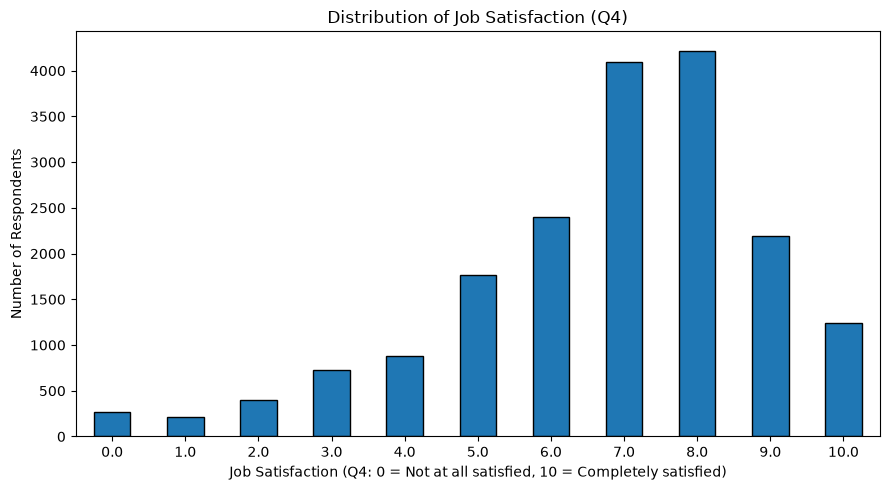


--- Target Variable Distribution (Q4: Job Satisfaction) ---


,Count,Percentage (%)
Q4_Numeric,,
0.0,264,1.44
1.0,217,1.18
2.0,396,2.15
3.0,728,3.96
4.0,878,4.78
5.0,1761,9.58
6.0,2396,13.04
7.0,4096,22.28
8.0,4219,22.95


In [96]:
# Convert Q4 (Job satisfaction) string responses into numeric values
df_clean["Q4_Numeric"] = pd.to_numeric(
    df_clean["Q4"].astype(str).str.extract(r"(\d+)")[0], errors="coerce"
)

# Job satisfaction rating from 0-10 (ignoring no responses)
q4_order = [f"{i}" for i in range(11)]

# Create plot for the distribution of job satisfaction compared to number of respondants
plt.figure(figsize=(9, 5))
df_clean["Q4_Numeric"].value_counts().sort_index().plot(kind="bar", color="#1f77b4", edgecolor="black")

plt.xlabel("Job Satisfaction (Q4: 0 = Not at all satisfied, 10 = Completely satisfied)")
plt.ylabel("Number of Respondents")
plt.title("Distribution of Job Satisfaction (Q4)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("\n--- Target Variable Distribution (Q4: Job Satisfaction) ---")
target_counts = df_clean["Q4_Numeric"].value_counts().sort_index()
target_props = df_clean["Q4_Numeric"].value_counts(normalize=True).sort_index() * 100
target_summary = pd.DataFrame({"Count": target_counts, "Percentage (%)": target_props.round(2)})

display(target_summary)

In [97]:
# List null values in the all remaining features
print(list(np.sum(df_clean.isnull(), axis = 0)))

[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 8154, 2444, 4948, 1394, 551, 1139, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 48]


In [98]:
# List remaining features
print(list(df_clean.columns))

['ENTITY_ID', 'SAMPLE', 'MODE', 'RESPONDENT_DATE', 'EndDate', 'S1', 'Q1', 'Q2', 'Q3', 'Q4', 'Q5', 'Q6', 'Q6_CODED', 'Q6_TEXT', 'Q7', 'Q7_CODED', 'Q7_TEXT', 'Q8', 'Q9', 'Q10', 'Q11', 'Q12', 'Q12_TEXT', 'Q13', 'Q14', 'Q15', 'Q15_TEXT', 'Q16', 'Q16_TEXT', 'Q17', 'Q18', 'Q19', 'Q20', 'Q21', 'Q22', 'Q23', 'Q24', 'Q25A', 'Q25B', 'Q25C', 'Q25D', 'Q26_1', 'Q26_2', 'Q26_3', 'Q26_4', 'Q26_5', 'Q26_6', 'Q26_7', 'Q27', 'Q28', 'Q29', 'Q30', 'Q31A', 'Q31B', 'Q31C', 'Q32A', 'Q32B', 'Q32C', 'Q33A', 'Q33B', 'Q33C', 'Q33D', 'Q33E', 'Q33F', 'Q33G', 'Q33H', 'Q33I', 'Q33J', 'Q34', 'Q35A', 'Q35B', 'Q35C', 'Q35D', 'Q36', 'Q37A', 'Q37B', 'Q37C', 'Q37D', 'Q37E', 'Q37F', 'Q37G', 'Q37H', 'Q37I', 'Q38A', 'Q38B', 'Q38C', 'Q39', 'Q40', 'Q41', 'Q42', 'Q43', 'Q44', 'Q45', 'Q46', 'Q46_TEXT', 'Q47', 'Q48', 'Q49', 'Q49_TEXT', 'Q50', 'Q51', 'Q52', 'Q53', 'Q54A', 'Q54B', 'Q54C', 'Q55', 'Q55_TEXT', 'Q56_1', 'Q56_2', 'Q56_3', 'Q56_4', 'Q57', 'Q58', 'Q59', 'Q60', 'Q61_1', 'Q61_2', 'Q61_3', 'Q61_4', 'Q61_5', 'Q62', 'Q63', 'Q6

In [99]:
# Drop the features that aren't related to job satisfaction
drop_columns = [
    'SAMPLE', 'MODE', 'RESPONDENT_DATE', 'S1', 'Q1', 'Q2', 'Q3', 'Q5', 'Q6_TEXT', 
    'Q7_CODED', 'Q7_TEXT', 'Q12', 'Q12_TEXT', 'Q13', 'Q15', 'Q15_TEXT', 'Q16_TEXT', 'Q26_1', 'Q26_2', 'Q26_3', 
    'Q26_4', 'Q26_5', 'Q26_6', 'Q26_7', 'Q29', 'Q37A', 'Q37B', 'Q37C', 'Q37D', 'Q37E', 'Q37F', 'Q37G', 'Q37H', 'Q37I',
    'Q38A', 'Q38B', 'Q38C', 'Q39','Q42', 'Q43', 'Q46', 'Q46_TEXT', 'Q47', 'Q48', 'Q49', 'Q49_TEXT', 'Q50',
    'Q55_TEXT', 'Q64_1', 'Q64_2', 'Q64_3', 'Q64_4', 'Q64_5', 'Q64_6','Q66_1', 'Q66_2', 'Q66_3', 'Q66_4', 'Q66_5', 'Q66_TEXT',
    'Q67', 'Q68', 'W2_STATUS', 'WEIGHT'
]

cols_to_drop = [col for col in drop_columns if col in df_clean.columns]
df_clean.drop(columns=cols_to_drop, inplace=True)

# Separate Features (X) and Target (y)
X = df_clean.drop(columns=['Q4', 'Q4_Numeric']).copy()
y = df_clean['Q4_Numeric'].copy()

In [100]:
# Locate the features that have the most missing values
missing_summary = df_clean.isnull().mean().sort_values(ascending=False)
print("Top Missing Variables:\n", missing_summary)

Top Missing Variables:
 Q31A    0.442455
Q31C    0.268490
Q31B    0.132617
Q32A    0.075642
Q32C    0.061805
          ...   
Q30     0.000000
Q28     0.000000
Q27     0.000000
Q25D    0.000000
Q35B    0.000000
Length: 90, dtype: float64


In [101]:
# Helper function to identify which race responded to the survey
def consolidate_race(row):
    if row.get("Q60") == "Yes":
        return "Hispanic/Latino"
    elif row.get("Q61_3") == "Selected":
        return "Black / African American"
    elif row.get("Q61_2") == "Selected":
        return "Asian"
    elif row.get("Q61_5") == "Selected":
        return "White"
    else:
        return "Other / Multiple"

df_clean["Race_Ethnicity"] = df_clean.apply(consolidate_race, axis=1)

# Summary of demographic counts
print("\n--- Demographic Sample Breakdown ---")
print("Gender (Q65):\n", df_clean["Q65"].value_counts(dropna=False))
print("\nRace/Ethnicity (Consolidated):\n", df_clean["Race_Ethnicity"].value_counts(dropna=False),)


--- Demographic Sample Breakdown ---
Gender (Q65):
 Q65
Female         9266
Male           8912
Nonbinary       163
No response      88
Name: count, dtype: int64

Race/Ethnicity (Consolidated):
 Race_Ethnicity
Other / Multiple    15888
Hispanic/Latino      2541
Name: count, dtype: int64


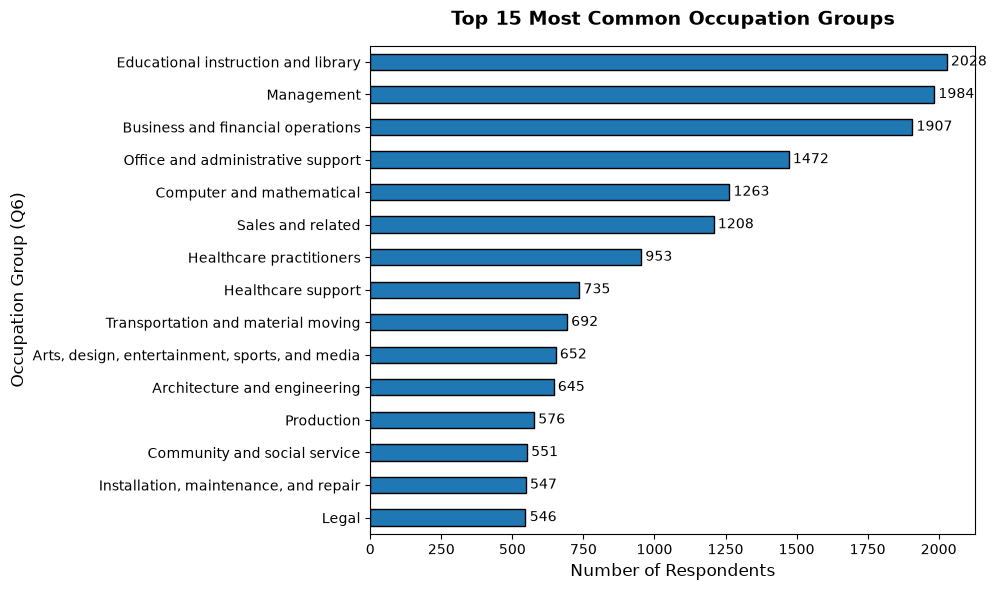

In [102]:
# Create plot for the top 15 occupation groups that completed the survey
plt.figure(figsize=(10, 6))
occ_counts = df_clean["Q6"].value_counts().head(15).sort_values(ascending=True)

ax1 = occ_counts.plot(kind="barh", color="#1f77b4", edgecolor="black")
plt.title("Top 15 Most Common Occupation Groups", fontsize=14, pad=15, fontweight="bold",)
plt.xlabel("Number of Respondents", fontsize=12)
plt.ylabel("Occupation Group (Q6)", fontsize=12)

for index, value in enumerate(occ_counts):
    ax1.text(value + 15, index, str(value), va="center", fontsize=10)

plt.tight_layout()
plt.show()

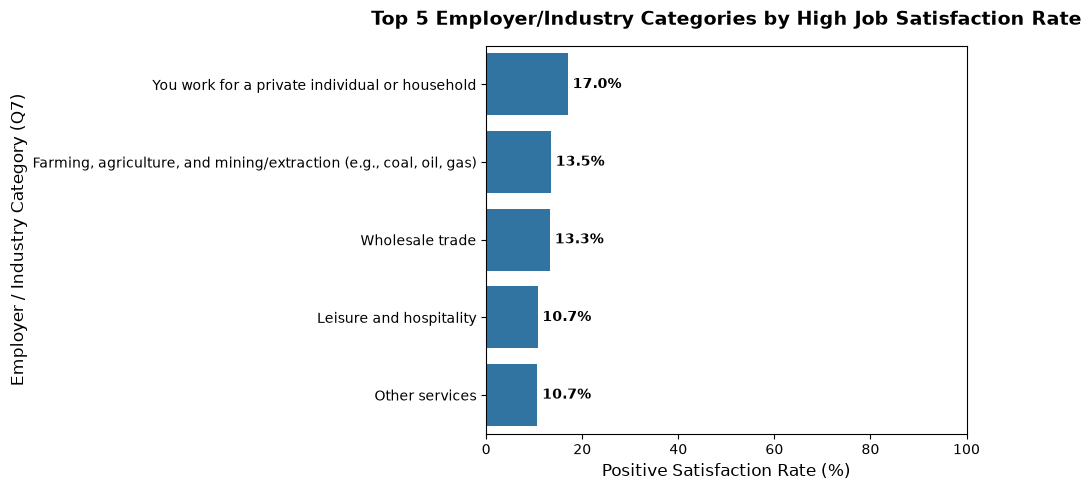

In [103]:
# Crosstab of Organization/Employer Type (Q7) vs Job Satisfaction (Q4)
industry_xtab = (pd.crosstab(df_clean["Q7"], df_clean["Q4"], normalize="index") * 100)

# Define positive satisfaction categories (e.g., 'Completely satisfied' / 'Very satisfied')
positive_cols = [c for c in industry_xtab.columns if "satisfied" in str(c).lower() and "dis" not in str(c).lower()]
industry_xtab["Satisfaction_Rate"] = industry_xtab[positive_cols].sum(axis=1)

top_5_industries = industry_xtab.sort_values(by="Satisfaction_Rate", ascending=False).head(5)

plt.figure(figsize=(10, 5))

sns.barplot(x=top_5_industries["Satisfaction_Rate"], y=top_5_industries.index)

plt.title("Top 5 Employer/Industry Categories by High Job Satisfaction Rate", fontsize=14, pad=15, fontweight="bold",)
plt.xlabel("Positive Satisfaction Rate (%)", fontsize=12)
plt.ylabel("Employer / Industry Category (Q7)", fontsize=12)
plt.xlim(0, 100)

for idx, val in enumerate(top_5_industries["Satisfaction_Rate"]):
    plt.text(val + 1, idx, f"{val:.1f}%", va="center", fontweight="bold")

plt.tight_layout()
plt.show()

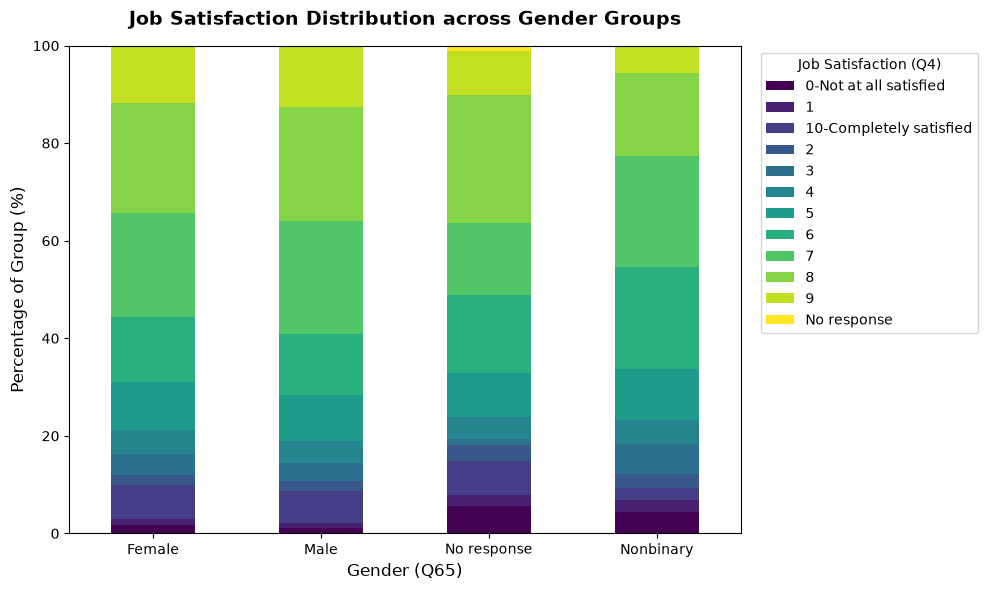

In [104]:
# Job satisfaction distirbution across gender groups
gender_sat = (pd.crosstab(df_clean["Q65"], df_clean["Q4"], normalize="index") * 100)

ax3 = gender_sat.plot( kind="bar", stacked=True, colormap="viridis", figsize=(10, 6))

# Plot for job satisfaction distribution across gender groups
plt.title("Job Satisfaction Distribution across Gender Groups", fontsize=14,pad=15, fontweight="bold",)
plt.xlabel("Gender (Q65)", fontsize=12)
plt.ylabel("Percentage of Group (%)", fontsize=12)

plt.legend(title="Job Satisfaction (Q4)", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

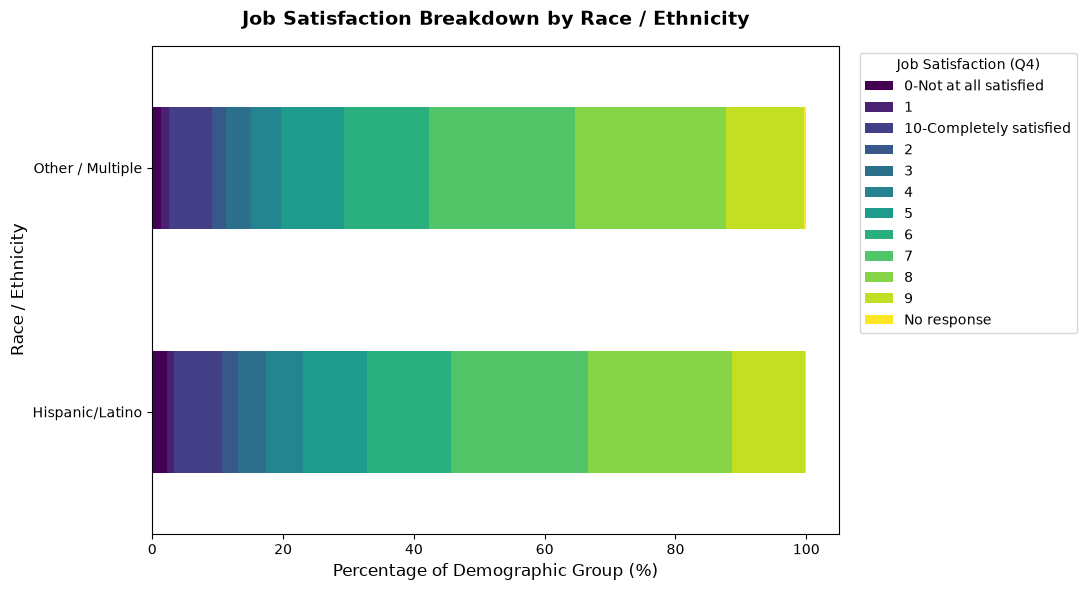

In [105]:
# Job satsfaction by race/ethnicity
race_sat = (pd.crosstab(df_clean["Race_Ethnicity"], df_clean["Q4"], normalize="index")* 100)

ax4 = race_sat.plot(kind="barh", stacked=True, colormap="viridis", figsize=(11, 6))

# Plot to display job satisfaction by race/ethicity
plt.title( "Job Satisfaction Breakdown by Race / Ethnicity",fontsize=14, pad=15, fontweight="bold",)

plt.xlabel("Percentage of Demographic Group (%)", fontsize=12)
plt.ylabel("Race / Ethnicity", fontsize=12)
plt.legend(title="Job Satisfaction (Q4)", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

--- Unified Race / Ethnicity Distribution (%) ---


Race_Ethnicity
White                            66.319388
Hispanic or Latino               13.788051
Black or African American        11.047805
Asian                             4.156492
Multi-Racial                      3.272017
Indigenous / Pacific Islander     0.824787
No Response / Other               0.591459
Name: proportion, dtype: float64

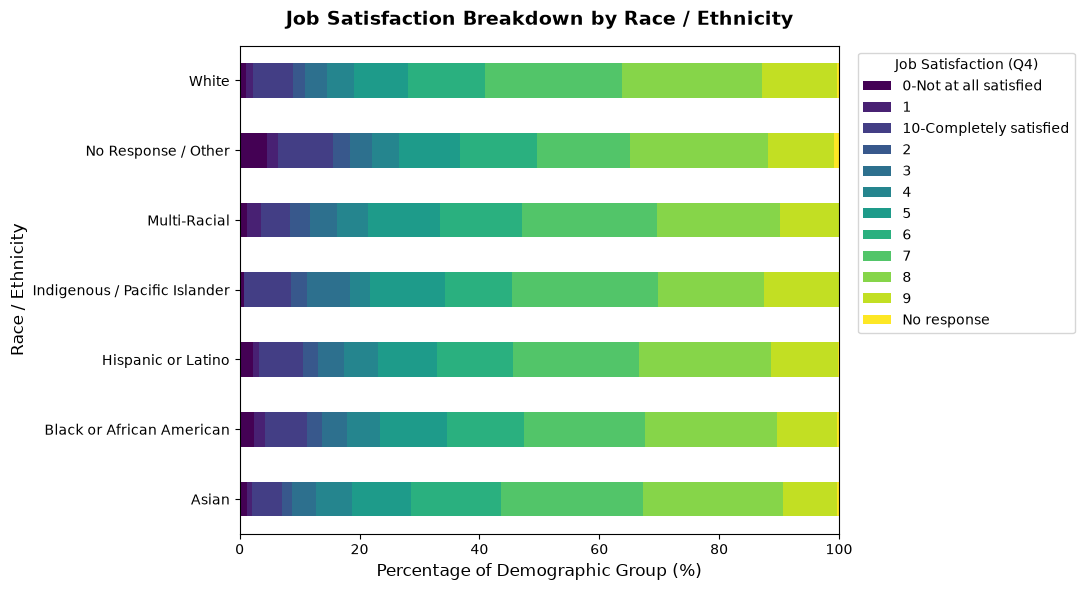

In [106]:
import matplotlib.pyplot as plt
import pandas as pd

def get_race_data(row):
    q60_val = str(row.get('Q60', '')).lower()
    if 'yes' in q60_val or q60_val == '1':
        return 'Hispanic or Latino'
    
    is_white = str(row.get('Q61_5', '')).lower() in ['1', 'yes', 'true', 'selected', 'white']
    is_black = str(row.get('Q61_3', '')).lower() in ['1', 'yes', 'true', 'selected', 'black or african american']
    is_asian = str(row.get('Q61_2', '')).lower() in ['1', 'yes', 'true', 'selected', 'asian']
    is_native = str(row.get('Q61_1', '')).lower() in ['1', 'yes', 'true', 'selected', 'american indian or alaskan native']
    is_pi = str(row.get('Q61_4', '')).lower() in ['1', 'yes', 'true', 'selected', 'native hawaiian or pacific islander']
    
    races_checked = sum([is_white, is_black, is_asian, is_native, is_pi])
    
    if races_checked > 1:
        return 'Multi-Racial'
    elif is_black:
        return 'Black or African American'
    elif is_white:
        return 'White'
    elif is_asian:
        return 'Asian'
    elif is_native or is_pi:
        return 'Indigenous / Pacific Islander'
    else:
        return 'No Response / Other'

# Create the unified column on df and df_clean
df['Race_Ethnicity'] = df.apply(get_race_data, axis=1)

# Ensure df_clean also receives the new feature
df_clean = df.dropna(subset=["Q4"]).copy()

print("--- Unified Race / Ethnicity Distribution (%) ---")
display(df_clean['Race_Ethnicity'].value_counts(normalize=True) * 100)

# Plot
race_sat = (pd.crosstab(df_clean["Race_Ethnicity"], df_clean["Q4"], normalize="index") * 100)

ax4 = race_sat.plot(kind="barh", stacked=True, colormap="viridis", figsize=(11, 6))

plt.title("Job Satisfaction Breakdown by Race / Ethnicity", fontsize=14, pad=15, fontweight="bold")
plt.xlabel("Percentage of Demographic Group (%)", fontsize=12)
plt.ylabel("Race / Ethnicity", fontsize=12)
plt.legend(title="Job Satisfaction (Q4)", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

In [107]:
job_quality_vars = ['Q18', 'Q19', 'Q20', 'Q21', 'Q22', 'Q23', 'Q24','Q25A', 'Q25B', 'Q25C', 'Q25D', 'Q31A', 'Q31B', 'Q31C',
    'Q32A', 'Q32B', 'Q32C', 'Q33A', 'Q33B', 'Q33C', 'Q33D', 'Q33E', 'Q33F', 'Q33G', 'Q33H', 'Q33I', 'Q33J',
    'Q34', 'Q35A', 'Q35B', 'Q35C', 'Q35D', 'Q36', 'Q40','Q41']

job_quality_vars = [col for col in job_quality_vars if col in X.columns]

display(X[job_quality_vars].head())

,Q18,Q19,Q20,Q21,Q22,Q23,Q24,Q25A,Q25B,Q25C,...,Q33I,Q33J,Q34,Q35A,Q35B,Q35C,Q35D,Q36,Q40,Q41
0,0 days,0 days,40,48,40,Sometimes,"At least 2 weeks, but less than 3 weeks",No input,No input,No input,...,Strongly disagree,Somewhat agree,No,Yes,No,No,No,Somewhat agree,"$2,001-$3,000",Strongly agree
1,1 day,2 days,38,38,38,Rarely,Always work the same schedule,No input,No input,Some input,...,Strongly agree,Strongly agree,No,Yes,No,Yes,No,Strongly agree,"$3,001-$4,000",Strongly agree
2,5 days,5 days,40,40,40,Rarely,Always work the same schedule,No input,No input,Some input,...,Strongly agree,Strongly agree,Yes,No,No,No,No,Strongly agree,"$6,001-$8,000",Strongly agree
3,0 days,0 days,44,50,40,Sometimes,"More than 1 day, but less than 7 days",A lot of input,A lot of input,A lot of input,...,Somewhat agree,Strongly agree,Not applicable,Not applicable,Not applicable,Not applicable,Not applicable,Strongly agree,"$4,001-$5,000",Strongly agree
4,0 days,Not possible for your job,40,56,40,Never,Always work the same schedule,No input,No input,No input,...,Somewhat disagree,Somewhat disagree,Yes,Yes,No,No,No,Somewhat disagree,"$3,001-$4,000",Somewhat agree


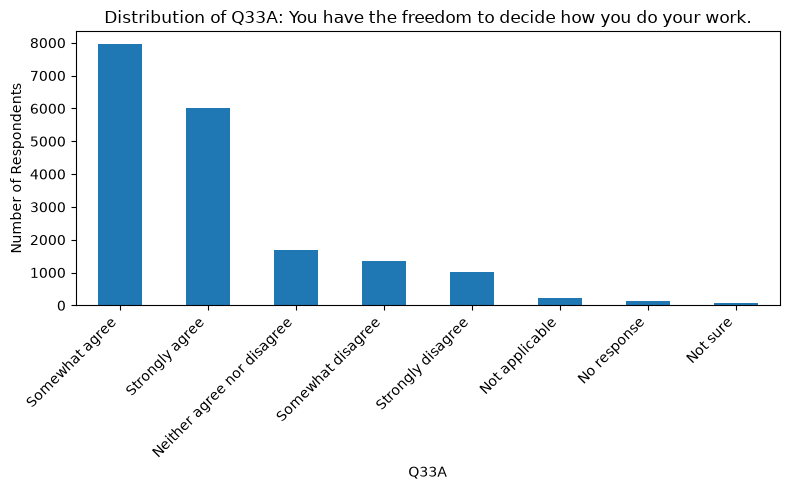

In [108]:
def plot_category_counts(df, column, figsize=(8, 5)):
    counts = df[column].value_counts(dropna=False)

    plt.figure(figsize=figsize)
    counts.plot(kind='bar')

    plt.title(f"Distribution of Q33A: You have the freedom to decide how you do your work.")
    plt.xlabel(column)
    plt.ylabel("Number of Respondents")
    plt.xticks(rotation=45, ha='right')

    plt.tight_layout()
    plt.show()
    
plot_category_counts(df_clean, 'Q33A')

Q4,0-Not at all satisfied,1,10-Completely satisfied,2,3,4,5,6,7,8,9,No response
Q33A,,,,,,,,,,,,
Neither agree nor disagree,2.003536,1.296405,3.476724,2.710666,6.364172,7.012375,14.731880,16.735415,22.687095,16.381850,6.128462,0.471420
No response,2.205882,2.941176,8.088235,5.147059,5.147059,5.147059,11.764706,9.558824,21.323529,17.647059,11.029412,0.000000
Not applicable,1.408451,3.755869,14.084507,2.816901,3.755869,4.225352,7.981221,11.737089,19.248826,18.309859,12.206573,0.469484
Not sure,6.451613,4.838710,3.225806,4.838710,3.225806,6.451613,17.741935,14.516129,14.516129,14.516129,9.677419,0.000000
Somewhat agree,0.754527,0.880282,3.609155,1.685111,3.231891,4.891851,9.519618,15.266600,25.842555,24.308350,9.796278,0.213783
Somewhat disagree,3.037037,2.370370,2.296296,5.555556,8.962963,8.666667,15.703704,18.000000,18.592593,12.666667,4.074074,0.074074
Strongly agree,0.681516,0.382314,13.098404,0.847739,1.645612,2.277261,6.033910,8.045213,19.697473,27.809176,19.232048,0.249335
Strongly disagree,7.776670,5.483549,2.991027,7.377866,12.562313,9.571286,13.459621,12.362911,14.057827,9.172483,4.586241,0.598205


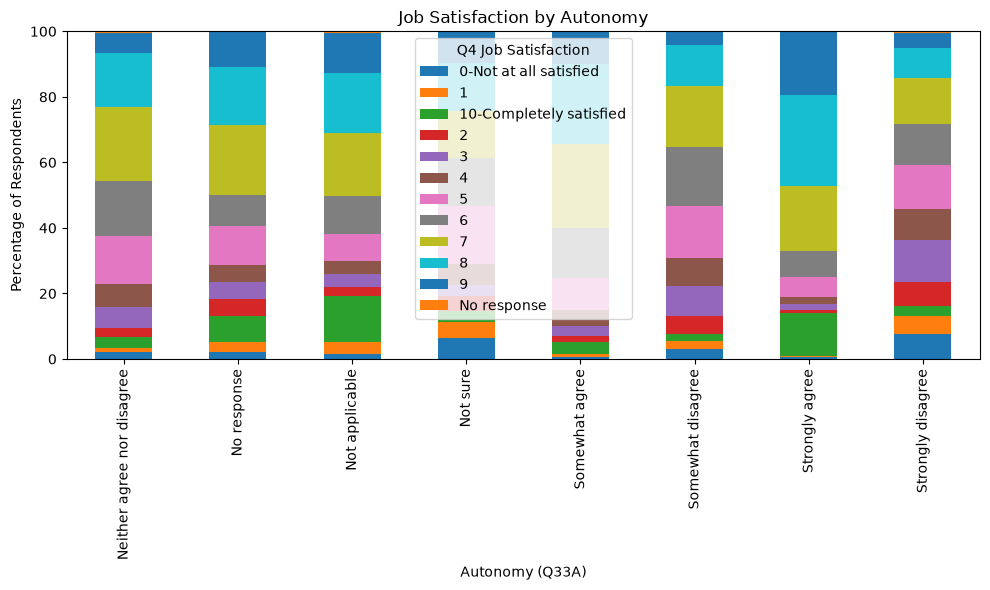

In [109]:
ct = pd.crosstab(df_clean['Q33A'], df['Q4'], normalize='index') * 100

display(ct)

ct.plot(kind='bar', stacked=True, figsize=(10, 6))

plt.title("Job Satisfaction by Autonomy")
plt.xlabel("Autonomy (Q33A)")
plt.ylabel("Percentage of Respondents")
plt.legend(title="Q4 Job Satisfaction")

plt.tight_layout()
plt.show()

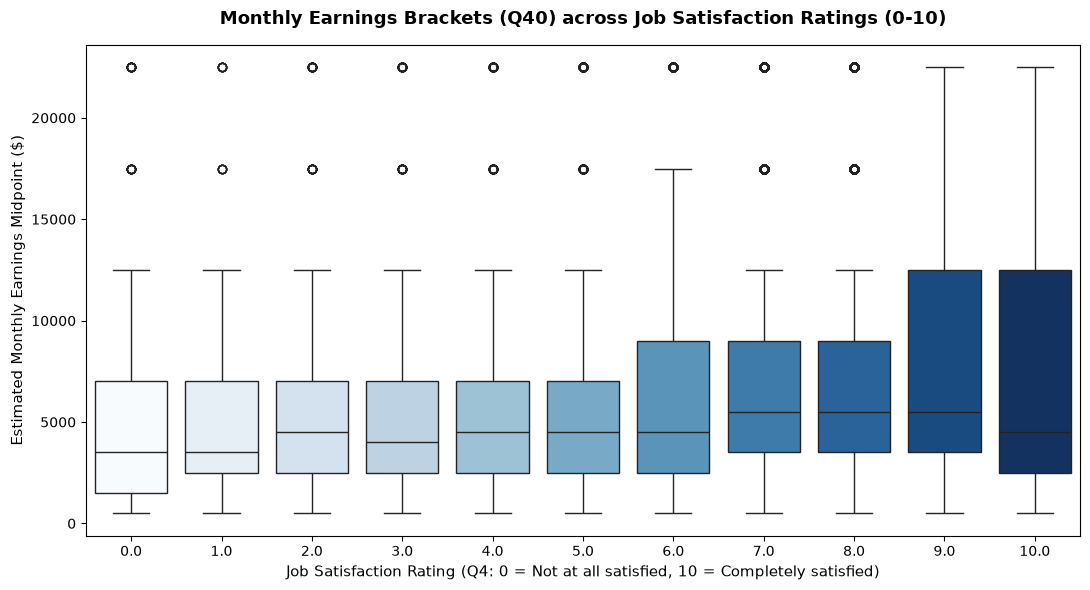

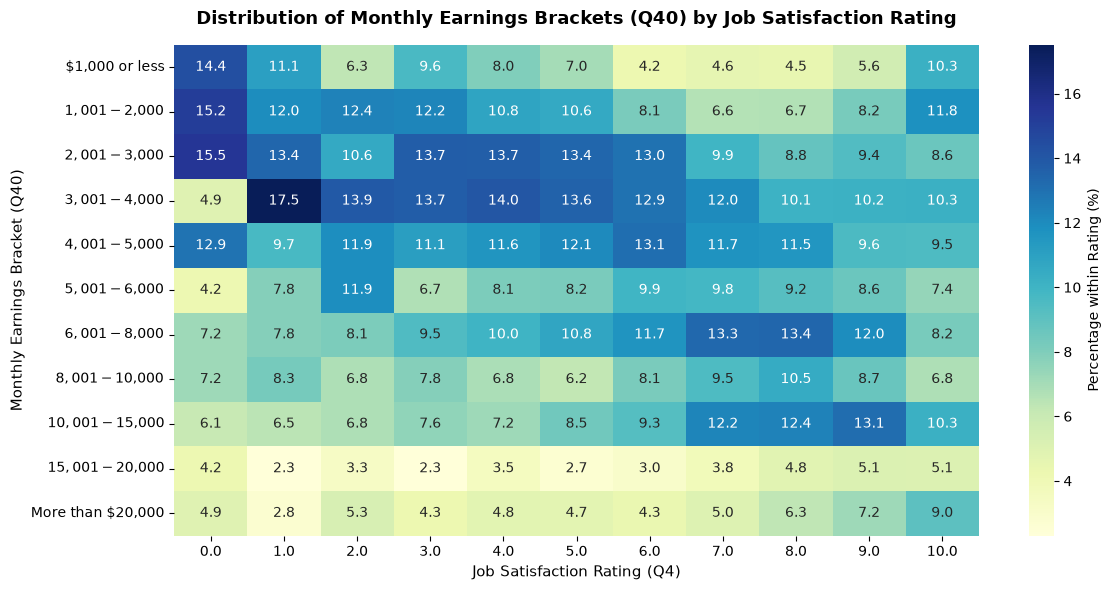

/var/folders/zg/747my4dd0dd82wrv7jq9djjm0000gn/T/ipykernel_8510/300132988.py:56: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax_pto = sns.barplot(


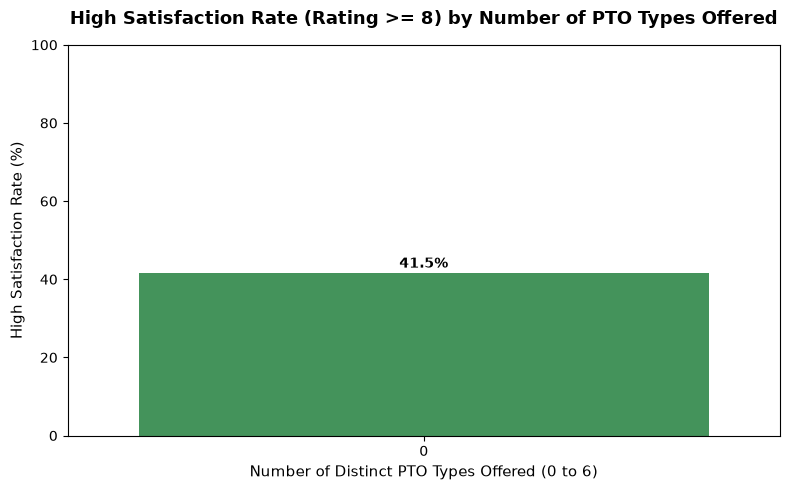

In [110]:
df_clean["Q4_Numeric"] = pd.to_numeric(df_clean["Q4"].astype(str).str.extract(r"(\d+)")[0], errors="coerce")

# 2. Map Q40 Income Brackets to Midpoints
q40_income_midpoints = {
    "$1,000 or less": 500, "$1,001-$2,000": 1500, "$2,001-$3,000": 2500, "$3,001-$4,000": 3500, "$4,001-$5,000": 4500,
    "$5,001-$6,000": 5500, "$6,001-$8,000": 7000, "$8,001-$10,000": 9000, "$10,001-$15,000": 12500, "$15,001-$20,000": 17500,
    "More than $20,000": 22500
}

df_clean["Q40_Numeric"] = df_clean["Q40"].map(q40_income_midpoints)

# 3. Earnings Boxplot
plt.figure(figsize=(11, 6))
sns.boxplot(
    data=df_clean.dropna(subset=["Q40_Numeric", "Q4_Numeric"]),  x="Q4_Numeric", y="Q40_Numeric", hue="Q4_Numeric",
    palette="Blues", legend=False
)
plt.title("Monthly Earnings Brackets (Q40) across Job Satisfaction Ratings (0-10)", fontsize=13, pad=15, fontweight="bold")
plt.xlabel("Job Satisfaction Rating (Q4: 0 = Not at all satisfied, 10 = Completely satisfied)", fontsize=11)
plt.ylabel("Estimated Monthly Earnings Midpoint ($)", fontsize=11)
plt.tight_layout()
plt.show()

# 4. Earnings Heatmap Alternative View
q40_order = [
    "$1,000 or less", "$1,001-$2,000", "$2,001-$3,000", "$3,001-$4,000", 
    "$4,001-$5,000", "$5,001-$6,000", "$6,001-$8,000", "$8,001-$10,000", 
    "$10,001-$15,000", "$15,001-$20,000", "More than $20,000"
]

plt.figure(figsize=(12, 6))
q40_xtab = pd.crosstab(df_clean["Q40"], df_clean["Q4_Numeric"], normalize="columns") * 100
q40_xtab = q40_xtab.reindex([cat for cat in q40_order if cat in q40_xtab.index])

sns.heatmap(q40_xtab, cmap="YlGnBu", annot=True, fmt=".1f", cbar_kws={'label': 'Percentage within Rating (%)'})
plt.title("Distribution of Monthly Earnings Brackets (Q40) by Job Satisfaction Rating", fontsize=13, pad=15, fontweight="bold")
plt.xlabel("Job Satisfaction Rating (Q4)", fontsize=11)
plt.ylabel("Monthly Earnings Bracket (Q40)", fontsize=11)
plt.tight_layout()
plt.show()

# 5. PTO Benefits vs High Satisfaction Rate (Q4 >= 8)
pto_cols = [f"Q26_{i}" for i in range(1, 7)]

def count_pto(row):
    return sum(
        1 for col in pto_cols 
        if row.get(col) in ["Selected", 1, "1", True]
    )

df_clean["PTO_Total_Types"] = df_clean.apply(count_pto, axis=1)

pto_sat = (df_clean.groupby("PTO_Total_Types")["Q4_Numeric"].apply(lambda x: (x >= 8).mean() * 100).reset_index())

plt.figure(figsize=(8, 5))
ax_pto = sns.barplot(
    data=pto_sat, x="PTO_Total_Types", y="Q4_Numeric", palette="Greens_d"
)
plt.title("High Satisfaction Rate (Rating >= 8) by Number of PTO Types Offered", fontsize=13, pad=15, fontweight="bold")
plt.xlabel("Number of Distinct PTO Types Offered (0 to 6)", fontsize=11)
plt.ylabel("High Satisfaction Rate (%)", fontsize=11)

for idx, row in pto_sat.iterrows():
    ax_pto.text(idx, row["Q4_Numeric"] + 1.5, f"{row['Q4_Numeric']:.1f}%", ha="center", fontweight="bold",)

plt.ylim(0, 100)
plt.tight_layout()
plt.show()

# Identify unique jobs in the data set to create cross walk with ONET

In [111]:
# Check unique values and data types in Q6
print(f"Total unique values in Q6: {df_clean['Q6'].nunique()}")
print("\nSample occupation entries:")
display(df_clean['Q6'].value_counts().head(20))

# If check text responses for unique jobs
if 'Q6_TEXT' in df.columns:
    print("\nSample free-text responses (Q6_TEXT):")
    display(df['Q6_TEXT'].dropna().head(10))

Total unique values in Q6: 26

Sample occupation entries:


Q6
Educational instruction and library               2028
Management                                        1984
Business and financial operations                 1907
Office and administrative support                 1472
Computer and mathematical                         1263
Sales and related                                 1208
Healthcare practitioners                           953
Healthcare support                                 735
Transportation and material moving                 692
Arts, design, entertainment, sports, and media     652
Architecture and engineering                       645
Production                                         576
Community and social service                       551
Installation, maintenance, and repair              547
Legal                                              546
Food preparation and service                       434
Life, physical, and social science                 405
Personal care and service                          369
Constru


Sample free-text responses (Q6_TEXT):


0                    
1                    
2                    
3    HOME IMPROVEMENT
4                 -98
5                 -98
6                    
7                 -98
8                    
9                    
Name: Q6_TEXT, dtype: str

# Data Cleaning Section

In [125]:
# Missing value detection

nan_count = np.sum(X.isnull(), axis=0)
nan_detected = nan_count != 0

missing_df = pd.DataFrame({
    'Missing Count': nan_count[nan_detected],
    'Missing Percentage (%)': (nan_count[nan_detected] / len(X)) * 100
}).sort_values(by='Missing Percentage (%)', ascending=False)

display(missing_df.head())

,Missing Count,Missing Percentage (%)


In [113]:
# Identify column types
is_int_or_float = (X.dtypes == 'int64') | (X.dtypes == 'float64')

# 5.1 Numeric Imputation (Median)
to_impute_num = nan_detected & is_int_or_float
num_cols_impute = X.columns[to_impute_num]

print(f"--- Imputing Numeric Columns ({len(num_cols_impute)}) ---")
for col in num_cols_impute:
    missing_qty = X[col].isnull().sum()
    median_val = X[col].median()
    X[col] = X[col].fillna(median_val)
    print(f"Filled {missing_qty} null values in numeric column '{col}' with median: {median_val}")

to_impute_cat = nan_detected & (~is_int_or_float)
cat_cols_impute = X.columns[to_impute_cat]

print(f"\n--- Imputing Categorical Columns ({len(cat_cols_impute)}) ---")
for col in cat_cols_impute:
    missing_qty = X[col].isnull().sum()
    mode_val = X[col].mode()[0] if not X[col].mode().empty else 'Missing'
    X[col] = X[col].fillna(mode_val)
    print(f"Filled {missing_qty} null values in categorical column '{col}' with mode: '{mode_val}'")

# 5.3 Winsorization on numeric columns (1st and 99th percentiles)
num_cols_all = X.select_dtypes(include=['number']).columns
print(f"\n--- Applying Outlier Winsorization to {len(num_cols_all)} Numeric Features (1% - 99%) ---")
for col in num_cols_all:
    X[col] = mstats.winsorize(X[col], limits=[0.01, 0.01])

--- Imputing Numeric Columns (0) ---

--- Imputing Categorical Columns (6) ---
Filled 8154 null values in categorical column 'Q31A' with mode: 'A little'
Filled 2444 null values in categorical column 'Q31B' with mode: 'Some'
Filled 4948 null values in categorical column 'Q31C' with mode: 'Some'
Filled 1394 null values in categorical column 'Q32A' with mode: 'Some'
Filled 551 null values in categorical column 'Q32B' with mode: 'A lot'
Filled 1139 null values in categorical column 'Q32C' with mode: 'Some'

--- Applying Outlier Winsorization to 2 Numeric Features (1% - 99%) ---


In [116]:
#Missing Value Detection & Imputation
nan_count = np.sum(X.isnull(), axis=0)
nan_detected = nan_count != 0

missing_df = pd.DataFrame({
    'Missing Count': nan_count[nan_detected],
    'Missing Percentage (%)': (nan_count[nan_detected] / len(X)) * 100
}).sort_values(by='Missing Percentage (%)', ascending=False)

print("Top Missing Variables:")
display(missing_df.head(15))

# Identify column types
is_int_or_float = (X.dtypes == 'int64') | (X.dtypes == 'float64')

# Numeric Imputation (Median)
to_impute_num = nan_detected & is_int_or_float
for col in X.columns[to_impute_num]:
    median_val = X[col].median()
    X[col] = X[col].fillna(median_val)

# Categorical Imputation (Mode)
to_impute_cat = nan_detected & (~is_int_or_float)
for col in X.columns[to_impute_cat]:
    mode_val = X[col].mode()[0] if not X[col].mode().empty else 'Missing'
    X[col] = X[col].fillna(mode_val)

# Outlier Winsorization on numeric columns (1st and 99th percentiles)
num_cols_all = X.select_dtypes(include=['number']).columns
for col in num_cols_all:
    X[col] = mstats.winsorize(X[col], limits=[0.01, 0.01])

Top Missing Variables:


,Missing Count,Missing Percentage (%)


In [117]:
# Checking categorical features for possible one-hot encoding
categorical_cols = list(X.select_dtypes(include=['object', 'category', 'string']).columns)
print(f"Categorical features identified for One-Hot Encoding ({len(categorical_cols)}):")
print(categorical_cols)

# One-hot encode categorical features (dropping first dummy to prevent collinearity)
X_encoded = pd.get_dummies(X, columns=categorical_cols, drop_first=True)

print(f"\nFinal Feature Matrix X_encoded Shape: {X_encoded.shape}")
print("Data cleaning pipeline completed successfully and ready for model training!")

Categorical features identified for One-Hot Encoding (86):
['EndDate', 'Q6', 'Q6_CODED', 'Q7', 'Q8', 'Q9', 'Q10', 'Q11', 'Q14', 'Q16', 'Q17', 'Q18', 'Q19', 'Q20', 'Q21', 'Q22', 'Q23', 'Q24', 'Q25A', 'Q25B', 'Q25C', 'Q25D', 'Q27', 'Q28', 'Q30', 'Q31A', 'Q31B', 'Q31C', 'Q32A', 'Q32B', 'Q32C', 'Q33A', 'Q33B', 'Q33C', 'Q33D', 'Q33E', 'Q33F', 'Q33G', 'Q33H', 'Q33I', 'Q33J', 'Q34', 'Q35A', 'Q35B', 'Q35C', 'Q35D', 'Q36', 'Q40', 'Q41', 'Q44', 'Q45', 'Q52', 'Q53', 'Q54A', 'Q54B', 'Q54C', 'Q55', 'Q56_1', 'Q56_2', 'Q56_3', 'Q56_4', 'Q57', 'Q58', 'Q59', 'Q60', 'Q61_1', 'Q61_2', 'Q61_3', 'Q61_4', 'Q61_5', 'Q62', 'Q63', 'Q65', 'RACE1', 'RACE2', 'RACE3', 'RACE4', 'RACE5', 'RACE6', 'RACE7', 'MARITAL_STATUS', 'EDUCATION', 'STATE', 'REGION', 'DIVISION', 'WORKER_TYPE']

Final Feature Matrix X_encoded Shape: (18429, 15724)
Data cleaning pipeline completed successfully and ready for model training!


In [118]:
categorical_cols = list(X.select_dtypes(include=['object', 'category', 'string']).columns)
print(f"Categorical features identified for One-Hot Encoding ({len(categorical_cols)})")

# One-hot encode categorical features
X_encoded = pd.get_dummies(X, columns=categorical_cols, drop_first=True)
print(f"Final Feature Matrix X_encoded Shape: {X_encoded.shape}")

# Diagnostics
remaining_nulls = X_encoded.isnull().sum().sum()
print(f"\n1. Null Value Verification: Total remaining NaNs = {remaining_nulls}")
assert remaining_nulls == 0, "Error: Null values still exist in the feature matrix!"

total_elements = X_encoded.shape[0] * X_encoded.shape[1]
zero_elements = (X_encoded == 0).sum().sum() + (X_encoded == False).sum().sum()
sparsity = (zero_elements / total_elements) * 100
print(f"2. One-Hot Encoding Sparsity: {sparsity:.2f}% of entries are zeros.")
print("Pipeline execution and diagnostics completed successfully!")

Categorical features identified for One-Hot Encoding (86)
Final Feature Matrix X_encoded Shape: (18429, 15724)

1. Null Value Verification: Total remaining NaNs = 0
2. One-Hot Encoding Sparsity: 199.22% of entries are zeros.
Pipeline execution and diagnostics completed successfully!


In [119]:
# Binary Label and Train-Test Split

# Convert Q4_Numeric into a binary classification label: 
# 1 = High Satisfaction (Rating >= 8), 0 = Lower Satisfaction (Rating < 8)
y_binary = (y >= 8).astype(int)

print("--- Binary Label Class Distribution ---")
print(y_binary.value_counts(normalize=True) * 100)

# Create training and test data sets (matching your lab split parameters)
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y_binary, test_size=0.33, random_state=1234
)

print(f"\nTraining set shape (X_train): {X_train.shape}")
print(f"Test set shape (X_test): {X_test.shape}")

--- Binary Label Class Distribution ---
Q4_Numeric
0    58.516469
1    41.483531
Name: proportion, dtype: float64

Training set shape (X_train): (12347, 15724)
Test set shape (X_test): (6082, 15724)


In [124]:
print(y_binary.value_counts(normalize=True) * 100)

from sklearn.preprocessing import StandardScaler

# Scale features so regularization (C) penalizes them evenly
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_encoded)

# Then split your scaled data
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y_binary, test_size=0.33, random_state=1234
)

model_check = LogisticRegression(C=1, max_iter=2000)
model_check.fit(X_train, y_train)

print(f"Number of non-zero coefficients: np.sum(model_check.coef_ != 0)")
print(f"Model intercept: {model_check.intercept_[0]:.4f}")



Q4_Numeric
0    58.516469
1    41.483531
Name: proportion, dtype: float64
Number of non-zero coefficients: np.sum(model_check.coef_ != 0)
Model intercept: -1.5026


In [120]:
def train_test_LR(X_train, y_train, X_test, y_test, c=1):
    '''
    Fit a Logistic Regression classifier to the training data X_train, y_train.
    Return the log loss and accuracy of resulting predictions on the test set.
    Parameters:
    C = Factor that controls inverse regularization strength.
    '''
    # 1. Create the scikit-learn LogisticRegression model object
    model = LogisticRegression(C=c, max_iter=2000, random_state=42)
    
    # 2. Fit the model to the training data
    model.fit(X_train, y_train)
    
    # 3. Make probability predictions
    probability_predictions = model.predict_proba(X_test)
    
    # 4. Compute log loss
    l_loss = log_loss(y_test, probability_predictions)
    
    # 5. Make class label predictions
    class_label_predictions = model.predict(X_test)
    
    # 6. Compute accuracy score
    acc_score = accuracy_score(y_test, class_label_predictions)
    
    return l_loss, acc_score

In [121]:
loss, acc = train_test_LR(X_train, y_train, X_test, y_test, c=1)

print(f"Baseline Log Loss (C=1): {loss:.5f}")
print(f"Baseline Accuracy (C=1): {acc:.5f}")

Baseline Log Loss (C=1): 0.67812
Baseline Accuracy (C=1): 0.58648


In [122]:
# Hyperparameter Tuning across Different Values of C
# Define 20 values of C spanning from 1e-10 to 1e9
cs = [10**i for i in range(-10, 10)]
cs_log10 = [np.log10(c) for c in cs]

ll_cs = []
acc_cs = []

for c in cs:
    ll, acc = train_test_LR(X_train, y_train, X_test, y_test, c)
    print(f"C of {c:e} -> Log Loss: {ll:.4f} | Accuracy: {acc:.4f}")
    ll_cs.append(ll)
    acc_cs.append(acc)

C of 1.000000e-10 -> Log Loss: 0.6781 | Accuracy: 0.5865
C of 1.000000e-09 -> Log Loss: 0.6781 | Accuracy: 0.5865
C of 1.000000e-08 -> Log Loss: 0.6781 | Accuracy: 0.5865
C of 1.000000e-07 -> Log Loss: 0.6781 | Accuracy: 0.5865
C of 1.000000e-06 -> Log Loss: 0.6781 | Accuracy: 0.5865
C of 1.000000e-05 -> Log Loss: 0.6781 | Accuracy: 0.5865
C of 1.000000e-04 -> Log Loss: 0.6781 | Accuracy: 0.5865
C of 1.000000e-03 -> Log Loss: 0.6781 | Accuracy: 0.5865
C of 1.000000e-02 -> Log Loss: 0.6781 | Accuracy: 0.5865
C of 1.000000e-01 -> Log Loss: 0.6781 | Accuracy: 0.5865
C of 1.000000e+00 -> Log Loss: 0.6781 | Accuracy: 0.5865
C of 1.000000e+01 -> Log Loss: 0.6781 | Accuracy: 0.5865
C of 1.000000e+02 -> Log Loss: 0.6781 | Accuracy: 0.5865
C of 1.000000e+03 -> Log Loss: 0.6781 | Accuracy: 0.5865
C of 1.000000e+04 -> Log Loss: 0.6781 | Accuracy: 0.5865
C of 1.000000e+05 -> Log Loss: 0.6781 | Accuracy: 0.5865
C of 1.000000e+06 -> Log Loss: 0.6781 | Accuracy: 0.5865
C of 1.000000e+07 -> Log Loss: 